# Gallstone feature engineering and model comparison

Build leakage-aware feature-selection and scaling pipelines for **logistic regression, XGBoost, random forest, and LightGBM** using a stratified **70% training / 15% validation / 15% test** split.

Workflow: split raw predictors → tune preprocessing, selection, and models with training-only cross-validation → compare the four finalists on validation data → choose one model → refit on training + validation → evaluate it once on the held-out test set.

The earlier EDA viewed the full dataset, so this is an internal holdout comparison, not a fully independent external validation. Target codes are retained; code `1` is the positive class without assigning an undocumented clinical meaning.

In [1]:
# If needed, uncomment and run once:
# %pip install numpy pandas matplotlib seaborn scipy scikit-learn xgboost lightgbm
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score, log_loss,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
RANDOM_STATE = 42
TARGET = "gallstone_status"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 1. Load raw data and verify the target

Only remove exported index columns when their values exactly match a zero- or one-based row sequence. Do not use PCA outputs or transformations fitted in the EDA notebook. Infinite predictor values become missing values; imputation happens later inside each pipeline.

In [2]:
candidates = [Path("dataset_gallstone"), Path("dataset_gallstone.xlsx"),
              Path("INFOSYS722/Iteration3_OpenStack/dataset_gallstone"),
              Path("INFOSYS722/Iteration3_OpenStack/dataset_gallstone.xlsx")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place the dataset beside this notebook or run from the projects directory.")
data = pd.read_excel(DATA_PATH) if DATA_PATH.suffix == ".xlsx" else pd.read_csv(DATA_PATH)
removed_index_cols = []
for c in list(data.columns):
    if str(c).startswith("Unnamed:") or not str(c).strip():
        values = pd.to_numeric(data[c], errors="coerce").to_numpy()
        if any(np.array_equal(values, np.arange(start, len(data) + start)) for start in [0, 1]):
            removed_index_cols.append(c)
data = data.drop(columns=removed_index_cols)
assert TARGET in data and data[TARGET].notna().all(), "Target must exist and have no missing values."
assert set(data[TARGET].unique()) == {0, 1}, "This notebook expects a binary target coded 0/1."
# A row-level split cannot protect against repeated patients without a patient identifier.
assert not data.duplicated().any(), "Review duplicate records before creating a row-level split."
X = data.drop(columns=TARGET).replace([np.inf, -np.inf], np.nan)
y = data[TARGET].astype(int)
print(f"Loaded {len(data)} rows and {X.shape[1]} raw predictors; removed index columns: {removed_index_cols}")
print("If patients have multiple records, replace the row split with patient-grouped splitting.")
display(data.head())

Loaded 319 rows and 38 raw predictors; removed index columns: ['Unnamed: 0']
If patients have multiple records, replace the row split with patient-grouped splitting.


,gallstone_status,age,gender,comorbidity,cad,hypothyroidism,hyperlipidemia,dm,height,weight,bmi,tbw,ecw,icw,ecf_tbw,tbfr_pct,lm_pct,protein_pct,vfr,bm,mm,obesity_pct,tfc,vfa,vma_kg,hfa,glucose,tc,ldl,hdl,triglyceride,ast,alt,alp,creatinine,gfr,crp,hgb,vitamin_d
0,0,50,0,0,0,0,0,0,185,92.8,27.1,52.9,21.2,31.7,40.0,19.2,80.84,18.88,9,3.7,71.4,23.4,17.8,10.6,39.7,0,102.0,250.0,175.0,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,30.5,43.1,19.5,23.6,45.0,32.8,67.20,16.68,15,3.2,60.3,38.8,31.0,18.4,32.7,0,94.0,172.0,108.0,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,31.2,47.2,20.1,27.1,43.0,27.3,72.67,16.35,15,3.3,62.9,41.7,24.9,16.2,34.0,0,103.0,179.0,124.0,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,24.0,41.4,17.0,24.4,41.0,15.8,84.19,16.90,6,2.9,54.1,9.0,10.7,6.5,29.2,1,69.0,173.0,73.0,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,28.3,51.4,20.0,31.4,39.0,20.0,80.02,16.81,8,3.5,68.2,28.6,17.9,10.4,37.4,2,109.0,205.0,154.0,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


## 2. Stratified 70/15/15 split

Reserve 30% first, then split that reserve equally into validation and test sets. Stratification approximately preserves target proportions. Whole-row rounding gives **223 / 48 / 48 rows** for this 319-row dataset. Validation selects the model family; test remains unused until the final evaluation.

In [3]:
X_train, X_reserved, y_train, y_reserved = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_reserved, y_reserved, test_size=0.50, stratify=y_reserved, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_valid) + len(X_test) == len(X)
split_summary = pd.DataFrame([
    {"split": name, "rows": len(target), "fraction": len(target) / len(y),
     "class_0": int((target == 0).sum()), "class_1": int((target == 1).sum())}
    for name, target in [("train", y_train), ("validation", y_valid), ("test", y_test)]
])
display(split_summary)
# Preserve row membership for reproducibility; these are source row indices, not patient IDs.
split_membership = pd.concat([
    pd.Series(name, index=frame.index, name="split")
    for name, frame in [("train", X_train), ("validation", X_valid), ("test", X_test)]
]).sort_index().rename_axis("source_row")

,split,rows,fraction,class_0,class_1
0,train,223,0.69906,113,110
1,validation,48,0.15047,24,24
2,test,48,0.15047,24,24


## 3. Feature engineering and selection strategy

- Treat the known coded fields as categorical, without assuming code meanings. One-hot encode them and ignore unseen categories at prediction time.
- Median-impute continuous measurements and most-frequent-impute categories. Each cross-validation fold fits its own imputer and encoder.
- For logistic regression, compare **StandardScaler** (mean/standard deviation) and **RobustScaler** (median/interquartile range). Robust scaling does not remove outliers. Trees use unscaled imputed numeric values because scaling is generally unnecessary for their splits.
- Use supervised **ANOVA F-score selection** to compare retaining 50%, 75%, or 100% of encoded features. Selection is fitted within each training fold. This is a simple baseline: univariate selection can miss interactions and retain redundant features. Its scores are exploratory rankings, not significance claims.

Choose preprocessing and hyperparameters by five-fold training ROC-AUC. The categorical roles below come from the existing dataset schema; no validation/test target associations are used for feature engineering.

In [4]:
coded_fields = ["gender", "comorbidity", "cad", "hypothyroidism", "hyperlipidemia", "dm", "hfa"]
categorical_features = [c for c in X_train if c in coded_fields or not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_features = [c for c in X_train if c not in categorical_features]
print("Numeric measurements:", numeric_features)
print("Categorical predictors:", categorical_features)
def make_preprocessor(scale_numeric=False):
    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler() if scale_numeric else "passthrough"),
    ])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("numeric", numeric, numeric_features),
        ("categorical", categorical, categorical_features),
    ], remainder="drop")
def make_pipeline(model, scale_numeric=False):
    return Pipeline([
        ("preprocess", make_preprocessor(scale_numeric)),
        ("select", SelectPercentile(score_func=f_classif)),
        ("model", model),
    ])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
experiments = {
    "Logistic regression": (
        make_pipeline(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), True),
        {"preprocess__numeric__scaler": [StandardScaler(), RobustScaler()],
         "select__percentile": [50, 75, 100], "model__C": [0.1, 1.0, 10.0]}),
    "Random forest": (
        make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE)),
        {"select__percentile": [50, 75, 100], "model__max_depth": [None, 5],
         "model__min_samples_leaf": [1, 4]}),
    "XGBoost": (
        make_pipeline(XGBClassifier(n_estimators=150, learning_rate=0.05, subsample=0.8,
                                    colsample_bytree=0.8, eval_metric="logloss", tree_method="hist",
                                    n_jobs=1, random_state=RANDOM_STATE)),
        {"select__percentile": [50, 75, 100], "model__max_depth": [2, 3],
         "model__reg_lambda": [1.0, 5.0]}),
    "LightGBM": (
        make_pipeline(LGBMClassifier(n_estimators=150, learning_rate=0.05,
                                     colsample_bytree=0.8, verbosity=-1, n_jobs=1,
                                     deterministic=True, force_col_wise=True,
                                     random_state=RANDOM_STATE)),
        {"select__percentile": [50, 75, 100], "model__num_leaves": [7, 15],
         "model__min_child_samples": [10, 20]}),
}
configuration_count = sum(len(ParameterGrid(grid)) for _, grid in experiments.values())
print(f"Search: {configuration_count} configurations × {cv.n_splits} folds = "
      f"{configuration_count * cv.n_splits} fits, plus finalist refits.")

Numeric measurements: ['age', 'height', 'weight', 'bmi', 'tbw', 'ecw', 'icw', 'ecf_tbw', 'tbfr_pct', 'lm_pct', 'protein_pct', 'vfr', 'bm', 'mm', 'obesity_pct', 'tfc', 'vfa', 'vma_kg', 'glucose', 'tc', 'ldl', 'hdl', 'triglyceride', 'ast', 'alt', 'alp', 'creatinine', 'gfr', 'crp', 'hgb', 'vitamin_d']
Categorical predictors: ['gender', 'comorbidity', 'cad', 'hypothyroidism', 'hyperlipidemia', 'dm', 'hfa']
Search: 54 configurations × 5 folds = 270 fits, plus finalist refits.


## 4. Tune using training data only

The search is deliberately small for this dataset. Training cross-validation selects each family's candidate; its best score is a tuning result, not an unbiased performance estimate. Models use a common fixed probability threshold of 0.5 for threshold-based metrics.

In [5]:
searches = {}
cv_rows = []
for name, (pipeline, grid) in experiments.items():
    search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=cv, n_jobs=1,
                          refit=True, return_train_score=False, error_score="raise")
    search.fit(X_train, y_train)
    searches[name] = search
    cv_rows.append({"model": name, "best_cv_roc_auc": search.best_score_,
                    "cv_fold_std": search.cv_results_["std_test_score"][search.best_index_],
                    "parameters": str(search.best_params_)})
    print(f"{name}: best training CV ROC-AUC = {search.best_score_:.3f}")
cv_summary = pd.DataFrame(cv_rows).sort_values("best_cv_roc_auc", ascending=False)
display(cv_summary)

Logistic regression: best training CV ROC-AUC = 0.831
Random forest: best training CV ROC-AUC = 0.822
XGBoost: best training CV ROC-AUC = 0.810
LightGBM: best training CV ROC-AUC = 0.812


,model,best_cv_roc_auc,cv_fold_std,parameters
0,Logistic regression,0.831207,0.106924,"{'model__C': 10.0, 'preprocess__numeric__scale..."
1,Random forest,0.821910,0.031745,"{'model__max_depth': None, 'model__min_samples..."
3,LightGBM,0.812001,0.030063,"{'model__min_child_samples': 20, 'model__num_l..."
2,XGBoost,0.809917,0.029699,"{'model__max_depth': 3, 'model__reg_lambda': 1..."


## 5. Validation comparison and selected features

ROC-AUC is the predeclared primary selection metric. Also report average precision (AP), accuracy, balanced accuracy, precision, recall, F1, and log loss. AP depends on prevalence. If validation ROC-AUC ties, use training CV ROC-AUC, then model name for reproducibility. Validation has only 48 rows, so small differences can be unstable.

Selected model by validation ROC-AUC: LightGBM
Logistic regression: 25 / 50 encoded features retained
Random forest: 25 / 50 encoded features retained
XGBoost: 37 / 50 encoded features retained
LightGBM: 37 / 50 encoded features retained


,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,log_loss,training_cv_auc
0,LightGBM,0.898,0.930,0.812,0.812,0.800,0.833,0.816,0.399,0.812
1,XGBoost,0.898,0.925,0.812,0.812,0.800,0.833,0.816,0.399,0.810
2,Logistic regression,0.894,0.912,0.792,0.792,0.818,0.750,0.783,0.494,0.831
3,Random forest,0.857,0.886,0.750,0.750,0.773,0.708,0.739,0.511,0.822


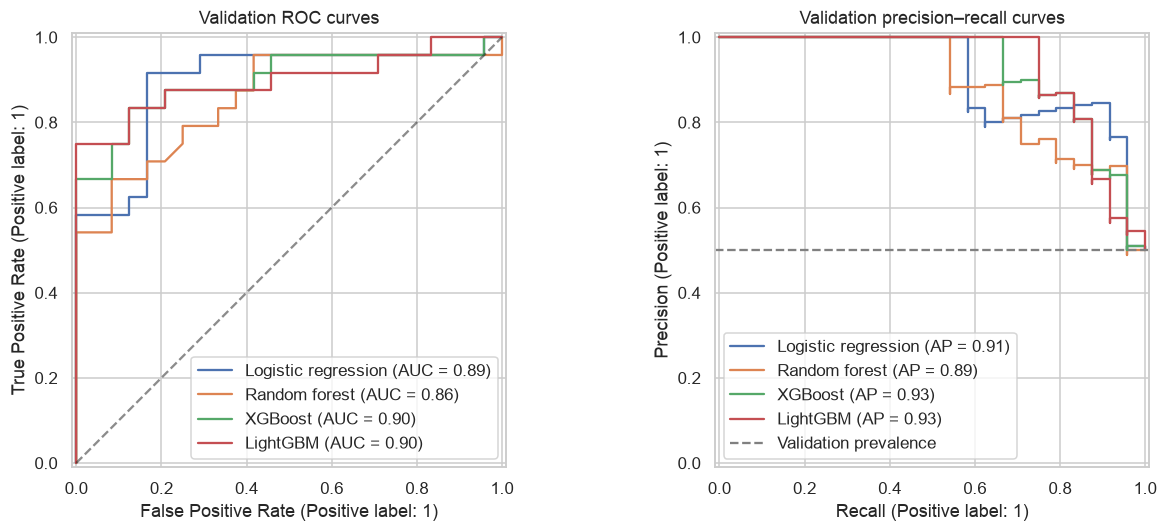

,feature,F_score,selected
0,numeric__vitamin_d,30.759890,True
1,numeric__crp,17.219178,True
2,numeric__bm,13.359681,True
3,numeric__lm_pct,8.799408,True
4,numeric__ecw,8.694854,True
5,numeric__tbfr_pct,8.311681,True
6,numeric__ast,7.908454,True
7,categorical__hfa_2,7.106403,True
8,categorical__hfa_1,6.496220,True
9,categorical__hyperlipidemia_1,6.460762,True


,feature,F_score,selected
0,numeric__vitamin_d,30.759890,True
1,numeric__crp,17.219178,True
2,numeric__bm,13.359681,True
3,numeric__lm_pct,8.799408,True
4,numeric__ecw,8.694854,True
5,numeric__tbfr_pct,8.311681,True
6,numeric__ast,7.908454,True
7,categorical__hfa_2,7.106403,True
8,categorical__hfa_1,6.496220,True
9,categorical__hyperlipidemia_1,6.460762,True


,feature,F_score,selected
0,numeric__vitamin_d,30.759890,True
1,numeric__crp,17.219178,True
2,numeric__bm,13.359681,True
3,numeric__lm_pct,8.799408,True
4,numeric__ecw,8.694854,True
5,numeric__tbfr_pct,8.311681,True
6,numeric__ast,7.908454,True
7,categorical__hfa_2,7.106403,True
8,categorical__hfa_1,6.496220,True
9,categorical__hyperlipidemia_1,6.460762,True


,feature,F_score,selected
0,numeric__vitamin_d,30.759890,True
1,numeric__crp,17.219178,True
2,numeric__bm,13.359681,True
3,numeric__lm_pct,8.799408,True
4,numeric__ecw,8.694854,True
5,numeric__tbfr_pct,8.311681,True
6,numeric__ast,7.908454,True
7,categorical__hfa_2,7.106403,True
8,categorical__hfa_1,6.496220,True
9,categorical__hyperlipidemia_1,6.460762,True


In [6]:
def evaluate_probabilities(target, probabilities):
    prediction = (probabilities >= 0.5).astype(int)
    return {"roc_auc": roc_auc_score(target, probabilities),
            "average_precision": average_precision_score(target, probabilities),
            "accuracy": accuracy_score(target, prediction),
            "balanced_accuracy": balanced_accuracy_score(target, prediction),
            "precision": precision_score(target, prediction, zero_division=0),
            "recall": recall_score(target, prediction, zero_division=0),
            "f1": f1_score(target, prediction, zero_division=0),
            "log_loss": log_loss(target, probabilities, labels=[0, 1])}
validation_rows = []
validation_probabilities = {}
for name, search in searches.items():
    probability = search.predict_proba(X_valid)[:, 1]
    validation_probabilities[name] = probability
    validation_rows.append({"model": name, **evaluate_probabilities(y_valid, probability),
                            "training_cv_auc": search.best_score_})
validation_results = pd.DataFrame(validation_rows).sort_values(
    ["roc_auc", "training_cv_auc", "model"], ascending=[False, False, True]).reset_index(drop=True)
display(validation_results.round(3))
selected_model_name = validation_results.loc[0, "model"]
print("Selected model by validation ROC-AUC:", selected_model_name)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, probability in validation_probabilities.items():
    RocCurveDisplay.from_predictions(y_valid, probability, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_valid, probability, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].axhline(y_valid.mean(), linestyle="--", color="grey", label="Validation prevalence")
axes[1].legend()
axes[0].set_title("Validation ROC curves"); axes[1].set_title("Validation precision–recall curves")
plt.tight_layout(); plt.show()
selected_feature_tables = {}
for name, search in searches.items():
    fitted = search.best_estimator_
    names = fitted.named_steps["preprocess"].get_feature_names_out()
    selector = fitted.named_steps["select"]
    table = pd.DataFrame({"feature": names, "F_score": selector.scores_, "selected": selector.get_support()})
    selected_feature_tables[name] = table
    print(f"{name}: {table.selected.sum()} / {len(table)} encoded features retained")
    display(table.loc[table.selected].sort_values("F_score", ascending=False).reset_index(drop=True))

## 6. Final held-out test evaluation

Freeze the winning model family and its tuned settings. Refit that entire pipeline on training plus validation (85%); preprocessing statistics and the selected feature set can change during this refit. Evaluate **only this winner** on test data. Do not use the test results to retune settings or select another family. A new independent dataset is needed if these results guide further changes.

**Experiment history:** this test split was already evaluated in the earlier three-model comparison. Adding LightGBM reuses that split, so the updated test results are a reused internal holdout, not a fresh independent confirmation. Model selection continues to use validation ROC-AUC only.


              precision    recall  f1-score   support

           0      0.833     0.833     0.833        24
           1      0.833     0.833     0.833        24

    accuracy                          0.833        48
   macro avg      0.833     0.833     0.833        48
weighted avg      0.833     0.833     0.833        48

Test ROC-AUC bootstrap 95% percentile interval: [0.809, 0.982]
This interval does not include model-selection or training-sample uncertainty.


,model,roc_auc,average_precision,accuracy,balanced_accuracy,precision,recall,f1,log_loss
0,LightGBM,0.908,0.932,0.833,0.833,0.833,0.833,0.833,0.409


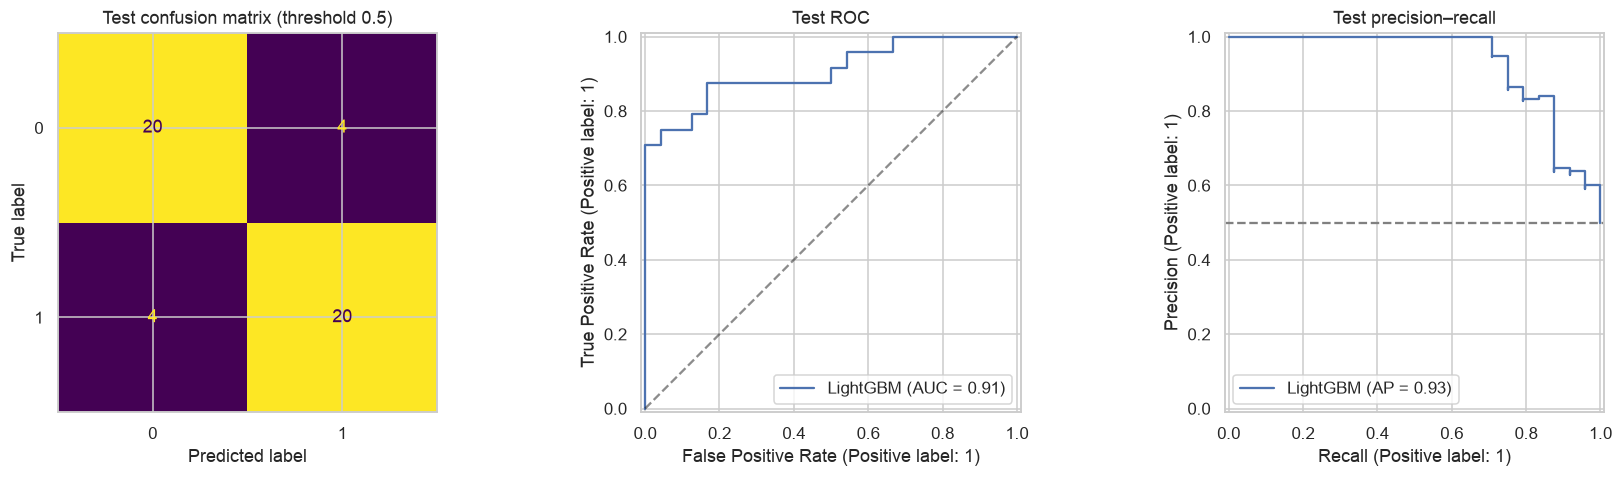

In [7]:
X_development = pd.concat([X_train, X_valid])
y_development = pd.concat([y_train, y_valid])
final_model = clone(searches[selected_model_name].best_estimator_)
final_model.fit(X_development, y_development)
test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.5).astype(int)
test_results = pd.DataFrame([{"model": selected_model_name,
                              **evaluate_probabilities(y_test, test_probability)}])
display(test_results.round(3))
print(classification_report(y_test, test_prediction, digits=3, zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name=selected_model_name)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[2], name=selected_model_name)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].axhline(y_test.mean(), linestyle="--", color="grey")
for ax, title in zip(axes, ["Test confusion matrix (threshold 0.5)", "Test ROC", "Test precision–recall"]):
    ax.set_title(title)
plt.tight_layout(); plt.show()
# Bootstrap uncertainty conditional on the fitted model and this small test sample.
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_auc = []
test_target_array = y_test.to_numpy()
for _ in range(2000):
    indices = rng.integers(0, len(y_test), size=len(y_test))
    if len(np.unique(test_target_array[indices])) == 2:
        bootstrap_auc.append(roc_auc_score(test_target_array[indices], test_probability[indices]))
auc_interval = np.quantile(bootstrap_auc, [0.025, 0.975])
print(f"Test ROC-AUC bootstrap 95% percentile interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]")
print("This interval does not include model-selection or training-sample uncertainty.")

## 7. Inspect the final fitted features and save results

For logistic regression, coefficients describe the encoded/scaled feature representation. For tree models, impurity/gain-based importances can favour some feature types and correlated predictors can share importance. Neither interpretation is causal. Feature ranks and selection may vary with a different split.

Save split membership, tuning summaries, validation/test metrics, and the final feature table beside the notebook. Keep `final_model` in memory for predictions with the original predictor columns.

Final numeric scaler: passthrough
Saved results to /Users/quyduong106/projects/INFOSYS722/Iteration3_OpenStack/feature_engineering_results


,feature,importance
19,numeric__crp,106
21,numeric__vitamin_d,60
13,numeric__vma_kg,57
10,numeric__obesity_pct,55
7,numeric__protein_pct,53
17,numeric__alp,52
20,numeric__hgb,48
12,numeric__vfa,46
15,numeric__ast,45
4,numeric__ecf_tbw,44


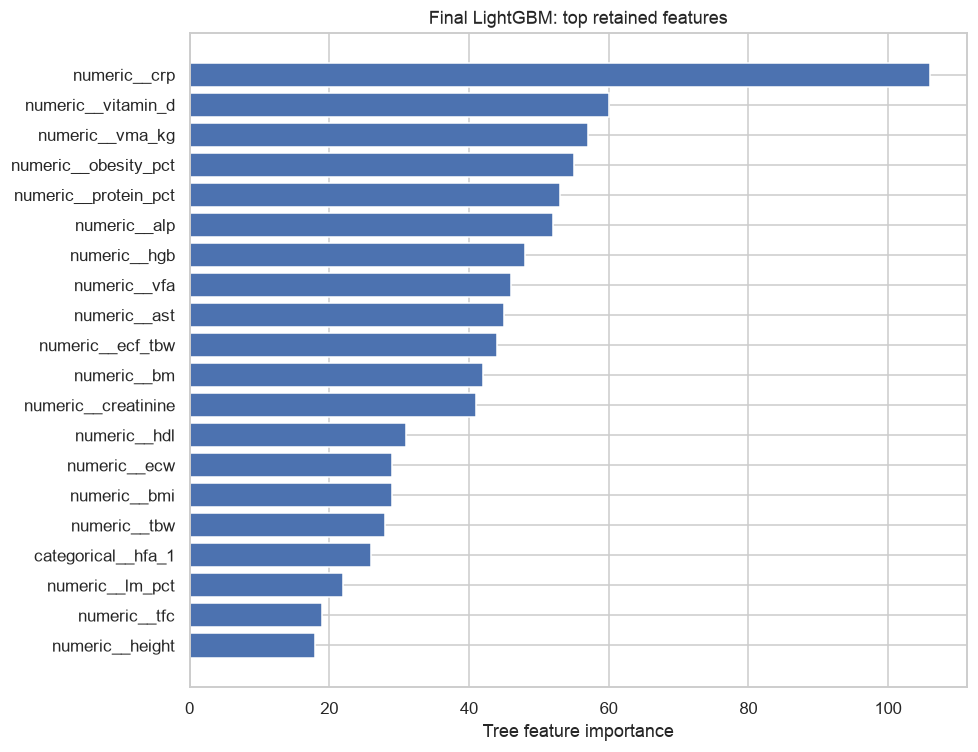

In [8]:
final_feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
final_selector = final_model.named_steps["select"]
retained_names = final_feature_names[final_selector.get_support()]
fitted_model = final_model.named_steps["model"]
if hasattr(fitted_model, "coef_"):
    importance = fitted_model.coef_[0]
    importance_label = "Coefficient (scaled/encoded inputs)"
else:
    importance = fitted_model.feature_importances_
    importance_label = "Tree feature importance"
final_features = pd.DataFrame({"feature": retained_names, "importance": importance})
final_features = final_features.sort_values("importance", key=abs, ascending=False)
print("Final numeric scaler:", final_model.named_steps["preprocess"].named_transformers_["numeric"].named_steps["scaler"])
display(final_features)
plot_features = final_features.head(20).sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_features.feature, plot_features.importance)
ax.set(title=f"Final {selected_model_name}: top retained features", xlabel=importance_label)
plt.tight_layout(); plt.show()
RESULTS_DIR = DATA_PATH.parent / "feature_engineering_results"
RESULTS_DIR.mkdir(exist_ok=True)
split_membership.to_csv(RESULTS_DIR / "split_membership.csv")
cv_summary.to_csv(RESULTS_DIR / "training_cv_summary.csv", index=False)
validation_results.to_csv(RESULTS_DIR / "validation_metrics.csv", index=False)
test_results.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
final_features.to_csv(RESULTS_DIR / "final_selected_features.csv", index=False)
print("Saved results to", RESULTS_DIR.resolve())